# Fermi-Pasta-Ulam problem

Author: Kevin Schäfers, kschaefers@uni-wuppertal.de
Date: 12.10.2026

---------------------------------------------------

This Jupyter notebook implements the hierarchical splitting methods used in 

*K. Schäfers, M. Günther: A hierarchical splitting approach for N-split differential equations*

to perform the numerical simulations for the FPU problem. The results are stored in `.npz` files and exported as TikZ files via `matplot2tikz`. For the numerical results reported in the paper, we have executed this Jupyter notebook with Python version 3.13.0 on a MacBook Pro 2021 with M1 Pro chip.


In [1]:
import numpy as np 
from scipy.integrate import solve_ivp # for the reference solution
import matplotlib.pyplot as plt # for plotting
import time # to measure CPU time
import timeit # to measure the cost of force evaluations
import matplot2tikz # convert pyplot to tikz, see https://github.com/ErwindeGelder/matplot2tikz

We start by specifying the number of stiff springs $m$ and the initial values of the FPU problem. The chain consists of $2m$ masses that are connected alternately by stiff linear springs and soft nonlinear springs. The state is $x = (p,q)$ with $p = (p^{\{\mathfrak{s}\}},p^{\{\mathfrak{f}\}})$ and $q = (q^{\{\mathfrak{s}\}},q^{\{\mathfrak{f}\}})$, where the components with superscript $\mathfrak{f}$ describe the elongations of the stiff springs. The frequency $\omega$ and the time interval are specified below, together with the numerical tests.

In [2]:
m = 3 # number of stiff springs (the chain has 2m masses and m+1 soft springs)


def make_x0(m, omega):
    """initial values of the FPU problem: x = (p, q), p = (p_s, p_f), q = (q_s, q_f)"""
    x0 = np.zeros(4*m)
    x0[0] = 1.0
    x0[m] = 1.0
    x0[2*m] = 1.0
    x0[3*m] = 1.0/omega
    return x0

Definition of the Hamiltonian, as well as the forces of the three partitions we are going to investigate. The Hamiltonian reads

$$\mathcal{H}(p,q) = T(p) + V^{\{\mathfrak{s}\}}(q) + V^{\{\mathfrak{f}\}}(q), \qquad T(p) = \tfrac{1}{2} \lVert p \rVert_2^2, \qquad V^{\{\mathfrak{f}\}}(q) = \tfrac{\omega^2}{2} \lVert q^{\{\mathfrak{f}\}} \rVert_2^2,$$

where the stiff springs give rise to the fast potential $V^{\{\mathfrak{f}\}}$ and the soft nonlinear springs form the slow potential

$$V^{\{\mathfrak{s}\}}(q) = \tfrac{1}{4} \left( \left( q_1^{\{\mathfrak{s}\}} - q_1^{\{\mathfrak{f}\}} \right)^4 + \left( q_m^{\{\mathfrak{s}\}} + q_m^{\{\mathfrak{f}\}} \right)^4 + \sum_{i=1}^{m-1} \left( q_{i+1}^{\{\mathfrak{s}\}} - q_{i+1}^{\{\mathfrak{f}\}} - q_i^{\{\mathfrak{s}\}} - q_i^{\{\mathfrak{f}\}} \right)^4 \right),$$

where the matrix $D$ collects the linear combinations of the position variables that are raised to the fourth power.

Besides the forces of the two potentials, we implement the force of the modified slow potential $V^{\{\mathfrak{s}\}} + c \, [V^{\{\mathfrak{s}\}},[T,V^{\{\mathfrak{s}\}}]]$ that is required by the force-gradient integrator, as well as the full right-hand side that is used for computing the reference solution.

In [3]:
# the m+1 linear combinations of the position variables that enter V_s
D = np.zeros((m + 1, 2*m))
D[0, 0], D[0, m] = 1, -1
for k in range(1, m):
    D[k, k], D[k, m+k], D[k, k-1], D[k, m+k-1] = 1, -1, -1, -1
D[m, m-1], D[m, 2*m-1] = -1, -1
DT = np.ascontiguousarray(D.T)
mask_f = np.concatenate((np.zeros(m), np.ones(m)))     # fast components q_f = q[m:]


def force_s(q):
    """-dV_s/dq = -D^T e^3."""
    return -(DT @ (D @ q)**3)


def force_f(q):
    """-dV_f/dq = -omega^2 q_f."""
    return (-omega**2 * mask_f) * q


def force_s_fg(q, c):
    """
    Force of the modified slow potential V_s + c [V_s,[T,V_s]] with [V_s,[T,V_s]] = -|grad V_s|^2:
    -grad V_s + 2c Hess V_s grad V_s, Hess V_s = D^T diag(3 e^2) D.
    """
    e = D @ q
    g = DT @ e**3
    return 2*c * (DT @ (3 * e * e * (D @ g))) - g


def f(t, x):
    """right-hand side of the full system (for the reference solution)"""
    q = x[2*m:]
    return np.concatenate((force_s(q) + force_f(q), x[:2*m]))


# Implementation of the Hierarchical Splitting Methods

We first collect the coefficients of the splitting methods for two-split systems that are assigned to the nodes of the splitting tree: the fourth-order method `OMF4` and the sixth-order method `OMF6` of Omelyan, Mryglod and Folk, as well as the fourth-order force-gradient integrator `ABACABACABA`.

The functions `fast_*` integrate the fast node $T + V^{\{\mathfrak{f}\}}$ over a time $\tau$ with $n$ micro steps of the respective two-split method, updating $p$ and $q$ in place. Since the slow kicks between two fast stages do not change $q$, the fast force at the end of a fast stage is still valid at the beginning of the next one. It is therefore passed in and returned (FSAL), which saves one fast force evaluation per stage.

In [ ]:
# OMF4 (Omelyan, Mryglod, Folk): kicks b_1, ..., b_6 and drifts a_1, ..., a_5 in the order b_1 a_1 b_2 ... a_5 b_6
OMF4_A = [0.253978510841060, -0.032302867652700, 1 - 2*0.253978510841060 - 2*(-0.032302867652700),
          -0.032302867652700, 0.253978510841060]
OMF4_B = [0.083983152628767, 0.682236533571909, 0.5 - 0.083983152628767 - 0.682236533571909,
          0.5 - 0.083983152628767 - 0.682236533571909, 0.682236533571909, 0.083983152628767]

# sixth-order splitting OMF6 (Omelyan, Mryglod, Folk 2003): kicks b_1, ..., b_8 and drifts a_2, ..., a_5, ..., a_2
# in the order b_1 a_2 b_2 a_3 b_3 a_4 b_4 a_5 b_4 a_4 b_3 a_3 b_2 a_2 b_1 (BABABABABABABAB)
OMF6_a2, OMF6_a3, OMF6_a4 = 0.2465881872786138, 0.6047073875057809, -0.4009869039788007
OMF6_b1, OMF6_b2, OMF6_b3 = 0.0833333333333333, 0.3977675859548440, -0.0393336931446257
OMF6_a5 = 1 - 2*(OMF6_a2 + OMF6_a3 + OMF6_a4)
OMF6_b4 = 0.5 - (OMF6_b1 + OMF6_b2 + OMF6_b3)
OMF6_A = [OMF6_a2, OMF6_a3, OMF6_a4, OMF6_a5, OMF6_a4, OMF6_a3, OMF6_a2]
OMF6_B = [OMF6_b1, OMF6_b2, OMF6_b3, OMF6_b4, OMF6_b4, OMF6_b3, OMF6_b2, OMF6_b1]

# fourth-order force-gradient integrator ABACABACABA (Omelyan, Mryglod, Folk 2003, eq. (72) with (78), mu = chi = 0)
ABACABACABA_RHO, ABACABACABA_THETA = 0.6419108866816235E-01, 0.1919807940455741E+00
ABACABACABA_VTHETA, ABACABACABA_LAM, ABACABACABA_XI = 0.1518179640276466E+00, 0.2158369476787619E+00, 0.9628905212024874E-03
ABACABACABA_MID = 0.5 - ABACABACABA_THETA - ABACABACABA_RHO
ABACABACABA_A = [ABACABACABA_RHO, ABACABACABA_THETA, ABACABACABA_MID,       # drift-type stages
                 ABACABACABA_MID, ABACABACABA_THETA, ABACABACABA_RHO]


def n_substeps(a, M, reweighting):
    """number of inner steps for an outer stage of length a*h (re-weighted or constant multirate factor)"""
    return int(np.ceil(np.abs(a) * M)) if reweighting else M


def fast_Strang(p, q, tau, n, F):
    """n Strang steps V_f(s/2) T(s) V_f(s/2), s = tau/n"""
    s = tau / n
    p += 0.5*s * F
    for k in range(n):
        q += s * p
        F = force_f(q)
        p += (s if k < n-1 else 0.5*s) * F
    return F


def fast_OMF4(p, q, tau, n, F):
    """n OMF4 steps"""
    s = tau / n
    p += OMF4_B[0]*s * F
    for k in range(n):
        for j in range(5):
            q += OMF4_A[j]*s * p
            F = force_f(q)
            b = OMF4_B[j+1] + (OMF4_B[0] if (j == 4 and k < n-1) else 0.0)
            p += b*s * F
    return F


def fast_OMF6(p, q, tau, n, F):
    """n OMF6 steps"""
    s = tau / n
    p += OMF6_B[0]*s * F
    for k in range(n):
        for j in range(7):
            q += OMF6_A[j]*s * p
            F = force_f(q)
            b = OMF6_B[j+1] + (OMF6_B[0] if (j == 6 and k < n-1) else 0.0)
            p += b*s * F
    return F


def fast_ABACABACABA(p, q, tau, n):
    """n steps of ABACABACABA with A = T, B = V_f; the drifts of consecutive steps are merged (no FSAL)"""
    s = tau / n
    k_fg = (2*(ABACABACABA_XI/ABACABACABA_LAM*s*s)*omega**4 - omega**2) * mask_f    # force_f_fg(q, xi/lambda s^2) = k_fg * q
    q += ABACABACABA_RHO*s * p
    for k in range(n):
        p += ABACABACABA_VTHETA*s * force_f(q)
        q += ABACABACABA_THETA*s * p
        p += ABACABACABA_LAM*s * (k_fg * q)
        q += ABACABACABA_MID*s * p
        p += (1 - 2*(ABACABACABA_LAM + ABACABACABA_VTHETA))*s * force_f(q)
        q += ABACABACABA_MID*s * p
        p += ABACABACABA_LAM*s * (k_fg * q)
        q += ABACABACABA_THETA*s * p
        p += ABACABACABA_VTHETA*s * force_f(q)
        q += (2*ABACABACABA_RHO if k < n-1 else ABACABACABA_RHO)*s * p


The composition schemes `BMs6p4` and `BMs10p6` of [Blanes & Moan, 2002] serve as reference methods. They are applied to the multirate Lie--Trotter method

$$\chi_\tau = \left( \varphi^{\{T\}}_{\tau/M} \circ \varphi^{\{V^{\{\mathfrak{f}\}}\}}_{\tau/M} \right)^M \circ \varphi^{\{V^{\{\mathfrak{s}\}}\}}_{\tau}$$

and its adjoint. Instead of calling the base scheme $2s$ times with step sizes $\alpha_i h$, we directly implement the composition to merge subsequent evaluations of the same flow, resulting in less flow evaluations while resulting in the same method.

For constant multirate factors, the composition inherits the order of its weights. With re-weighted multirate factors, the base scheme differs from stage to stage and the order drops to two.

In [5]:
BM_A = [0.0792036964311957, 0.353172906049774, -0.0420650803577195]
BM_A = BM_A + [1.0 - 2.0 * sum(BM_A)] + BM_A[::-1]
BM_B = [0.209515106613362, -0.143851773179818]
BM_B = BM_B + [0.5 - sum(BM_B)]
BM_B = BM_B + BM_B[::-1]
# equivalent composition  psi_h = chi_{al_12 h} o chi*_{al_11 h} o ... o chi_{al_2 h} o chi*_{al_1 h}
BM_ALPHA = [BM_A[0]]
for j in range(6):
    BM_ALPHA.append(BM_B[j] - BM_ALPHA[-1])
    if j < 5:
        BM_ALPHA.append(BM_A[j + 1] - BM_ALPHA[-1])

# BMs10p6: pair j consists of chi*_{c_{11-j} h} followed by chi_{c_j h}
BM10_C = [0.0985536835006498, -0.44734648269547816, -0.42511876779769087, 0.19560248860005314, -0.36276277925434486,
          0.34635818985072686, 0.23706391397812188, 0.49242637248987586, 0.31496061692769417, 0.05026276440039221]
BM10_ALPHA = [w for j in range(10) for w in (BM10_C[9-j], BM10_C[j])]


def LieTrotter_composition(x0, tspan, nsteps, M, reweighting, alpha):
    """
    Composition psi_h = chi_{al_{2s} h} o chi*_{al_{2s-1} h} o ... o chi_{al_2 h} o chi*_{al_1 h} of the multirate
    Lie-Trotter method
        chi_tau = (T_{tau/M} o V_{f,tau/M})^M o V_{s,tau}
    and its adjoint chi*_tau = V_{s,tau} o (V_{f,tau/M} o T_{tau/M})^M. In each pair chi_{al_{2j} h} o chi*_{al_{2j-1} h}
    the two slow kicks are merged into V_s((al_{2j-1} + al_{2j}) h), so that s slow evaluations per step remain.
    The fast kicks next to it act at the same positions and are merged as well, as are consecutive drifts.

    For constant M, the composition inherits the order of the composition weights; re-weighting (M_j = ceil(|al_j| M))
    reduces the order to two.

    Inputs:
        x0: initial condition (numpy array of shape (2d,))
        tspan: time interval (tuple (t0,tf))
        nsteps: number of macro time steps (int)
        M: number of micro steps for the fast part (int)
        reweighting: whether to use re-weighting of the multirate factor (bool)
        alpha: composition weights al_1, ..., al_{2s} (list)

    Outputs:
        t: time grid (numpy array of shape (nsteps+1,))
        x: solution at each time step (numpy array of shape (2d,nsteps+1))
    """
    d = len(x0)//2
    h = (tspan[1] - tspan[0])/nsteps
    t = np.linspace(tspan[0],tspan[1],nsteps+1)
    x = np.zeros((len(x0),nsteps+1))
    x[:,0] = x0
    p, q = x0[:d].copy(), x0[d:].copy()
    nsub = [n_substeps(al, M, reweighting) for al in alpha]

    drift = 0.0     # pending drift (in units of h) of the preceding chi, merged with the first drift of the next chi*
    for n in range(nsteps):
        for j in range(len(alpha)//2):
            a, na = alpha[2*j], nsub[2*j]
            b, nb = alpha[2*j+1], nsub[2*j+1]
            # chi*_{a h}: (T then V_f) x na, then V_s
            for k in range(na):
                q += (drift + a/na if k == 0 else a/na)*h * p
                if k < na-1:
                    p += a/na*h * force_f(q)
            # last V_f of chi*_{a h}, V_s of chi*_{a h} and chi_{b h}, first V_f of chi_{b h} merged
            p += (a/na + b/nb)*h * force_f(q) + (a + b)*h * force_s(q)
            # chi_{b h}: (V_f then T) x nb, the last drift is kept pending
            for k in range(1, nb):
                q += b/nb*h * p
                p += b/nb*h * force_f(q)
            drift = b/nb
        x[:d,n+1] = p
        x[d:,n+1] = q + drift*h * p

    return t,x


def BMs6p4(x0, tspan, nsteps, M, reweighting=False):
    """
    Six-stage composition method of order four from [Blanes & Moan 2002] applied to the multirate Lie-Trotter method
    and its adjoint (see LieTrotter_composition): 6 slow evaluations per step.
    Order four for constant M, order two with re-weighting.
    """
    return LieTrotter_composition(x0, tspan, nsteps, M, reweighting, BM_ALPHA)


def BMs10p6(x0, tspan, nsteps, M, reweighting=False):
    """
    Ten-stage composition method of order six from [Blanes & Moan 2002] applied to the multirate Lie-Trotter method
    and its adjoint (see LieTrotter_composition): 10 slow evaluations per step.
    Order six for constant M, order two with re-weighting.
    """
    return LieTrotter_composition(x0, tspan, nsteps, M, reweighting, BM10_ALPHA)


Implementation of the `HOMF4` method that uses the `OMF4` splitting method in both inner nodes, i.e. in the root node $\mathcal{H}$ and in the node $\mathcal{H}^{\{\mathfrak{f}\}} = T + V^{\{\mathfrak{f}\}}$.

In [ ]:
def HOMF4(x0, tspan, nsteps, mrfactor, reweighting=True):
    """
    Hierarchical splitting method for the three-split FPU problem T + V_s + V_f with OMF4 in both nodes:
    the root node splits V_s | (T + V_f), the fast node T + V_f is split into T | V_f and integrated by
    M_j = ceil(|a_j| mrfactor) OMF4 steps per root stage a_j h (or mrfactor steps without re-weighting).
    The outer slow kicks of consecutive steps are merged (FSAL), and the fast force at the end of a fast stage is re-used
    at the beginning of the next fast stage.

    Inputs:
        x0: initial condition (numpy array of shape (2d,))
        tspan: time interval (tuple (t0,tf))
        nsteps: number of macro time steps (int)
        mrfactor: multirate factor (int)
        reweighting: whether to use re-weighting of the multirate factor (bool, default: True)

    Outputs:
        t: time grid (numpy array of shape (nsteps+1,))
        x: solution at each time step (numpy array of shape (2d,nsteps+1))
    """
    d = len(x0)//2
    h = (tspan[1] - tspan[0])/nsteps
    t = np.linspace(tspan[0],tspan[1],nsteps+1)
    x = np.zeros((len(x0),nsteps+1))
    x[:,0] = x0
    p, q = x0[:d].copy(), x0[d:].copy()
    nsub = [n_substeps(a, mrfactor, reweighting) for a in OMF4_A]

    F = force_f(q)                             # fast force at the current positions, re-used by the next fast stage
    p += OMF4_B[0]*h * force_s(q)
    for n in range(nsteps):
        for j in range(5):
            F = fast_OMF4(p, q, OMF4_A[j]*h, nsub[j], F)
            if j < 4:
                p += OMF4_B[j+1]*h * force_s(q)
        val = force_s(q)                       # last slow kick of this step = first slow kick of the next step
        x[:d,n+1] = p + OMF4_B[5]*h * val
        x[d:,n+1] = q
        p += (OMF4_B[5] + OMF4_B[0])*h * val

    return t,x

It follows the implementation of the `COMP4` method that uses the `OMF4` splitting method in the root node $\mathcal{H}$, but the `Strang` splitting in the node $\mathcal{H}^{\{\mathfrak{f}\}}$. Due to the Strang splitting, the overall hierarchical splitting method is only convergent of second order.

We use this setup to highlight the concept of computational order: the order reduction comes from the sub-tree of the fast Hamiltonian. For sufficiently large multirate factor $M$ attached to the edge connecting the sub-tree to the remainder tree, the `COMP4` method achieves a *computational order* of four.

In [7]:
def COMP4(x0, tspan, nsteps, mrfactor, reweighting=True):
    """
    Hierarchical splitting method with OMF4 in the root node V_s | (T + V_f) and the second-order Strang splitting
    in the fast node T | V_f. The method is convergent of order two, but shows a computational order of four
    for sufficiently large multirate factors.

    Inputs and outputs as for HOMF4.
    """
    d = len(x0)//2
    h = (tspan[1] - tspan[0])/nsteps
    t = np.linspace(tspan[0],tspan[1],nsteps+1)
    x = np.zeros((len(x0),nsteps+1))
    x[:,0] = x0
    p, q = x0[:d].copy(), x0[d:].copy()
    nsub = [n_substeps(a, mrfactor, reweighting) for a in OMF4_A]

    F = force_f(q)                             # fast force at the current positions, re-used by the next fast stage
    p += OMF4_B[0]*h * force_s(q)
    for n in range(nsteps):
        for j in range(5):
            F = fast_Strang(p, q, OMF4_A[j]*h, nsub[j], F)
            if j < 4:
                p += OMF4_B[j+1]*h * force_s(q)
        val = force_s(q)
        x[:d,n+1] = p + OMF4_B[5]*h * val
        x[d:,n+1] = q
        p += (OMF4_B[5] + OMF4_B[0])*h * val

    return t,x

Implementation of the `HFG4` method that uses the force-gradient integrator `ABACABACABA` in both inner nodes. In the root node, the force-gradient term is evaluated for the modified slow potential; in the fast node, the force-gradient term of the quadratic fast potential is available in closed form, so that no additional force evaluation is required.

In [ ]:
def HFG4(x0, tspan, nsteps, mrfactor, reweighting=True):
    """
    Hierarchical splitting method with the fourth-order force-gradient integrator ABACABACABA in both nodes:
    root node with A = T + V_f (fast flows F) and B = V_s,
        F(rho h) V_s(vartheta h) F(theta h) V~_s(lambda h) F(mid h) V_s((1-2(lambda+vartheta)) h) F(mid h) V~_s(lambda h)
        F(theta h) V_s(vartheta h) F(rho h),   mid = 1/2 - theta - rho,   V~_s = V_s + xi/lambda h^2 [V_s,[T,V_s]],
    where each fast flow F(a h) is integrated by ceil(|a| mrfactor) steps of the same scheme for T | V_f.

    Inputs and outputs as for HOMF4.
    """
    d = len(x0)//2
    h = (tspan[1] - tspan[0])/nsteps
    t = np.linspace(tspan[0],tspan[1],nsteps+1)
    x = np.zeros((len(x0),nsteps+1))
    x[:,0] = x0
    p, q = x0[:d].copy(), x0[d:].copy()
    nsub = [n_substeps(a, mrfactor, reweighting) for a in ABACABACABA_A]
    c_fg = ABACABACABA_XI/ABACABACABA_LAM * h*h

    for n in range(nsteps):
        fast_ABACABACABA(p, q, ABACABACABA_RHO*h, nsub[0])
        p += ABACABACABA_VTHETA*h * force_s(q)
        fast_ABACABACABA(p, q, ABACABACABA_THETA*h, nsub[1])
        p += ABACABACABA_LAM*h * force_s_fg(q, c_fg)
        fast_ABACABACABA(p, q, ABACABACABA_MID*h, nsub[2])
        p += (1 - 2*(ABACABACABA_LAM + ABACABACABA_VTHETA))*h * force_s(q)
        fast_ABACABACABA(p, q, ABACABACABA_MID*h, nsub[3])
        p += ABACABACABA_LAM*h * force_s_fg(q, c_fg)
        fast_ABACABACABA(p, q, ABACABACABA_THETA*h, nsub[4])
        p += ABACABACABA_VTHETA*h * force_s(q)
        fast_ABACABACABA(p, q, ABACABACABA_RHO*h, nsub[5])
        x[:d,n+1] = p
        x[d:,n+1] = q

    return t,x

Implementation of the `HOMF6` method that uses the sixth-order splitting method `OMF6` in both inner nodes.

In [ ]:
def HOMF6(x0, tspan, nsteps, mrfactor, reweighting=True):
    """
    Sixth-order hierarchical splitting method with the OMF6 splitting (BABABABABABABAB) of Omelyan, Mryglod and Folk
    in both nodes: the root node splits V_s | (T + V_f), the fast node T + V_f is split into T | V_f and integrated by
    M_j = ceil(|a_j| mrfactor) OMF6 steps per root stage a_j h (or mrfactor steps without re-weighting).
    The outer slow kicks of consecutive steps are merged (FSAL), and the fast force at the end of a fast stage is re-used
    at the beginning of the next fast stage.

    Inputs and outputs as for HOMF4.
    """
    d = len(x0)//2
    h = (tspan[1] - tspan[0])/nsteps
    t = np.linspace(tspan[0],tspan[1],nsteps+1)
    x = np.zeros((len(x0),nsteps+1))
    x[:,0] = x0
    p, q = x0[:d].copy(), x0[d:].copy()
    nsub = [n_substeps(a, mrfactor, reweighting) for a in OMF6_A]

    F = force_f(q)                             # fast force at the current positions, re-used by the next fast stage
    p += OMF6_B[0]*h * force_s(q)
    for n in range(nsteps):
        for j in range(7):
            F = fast_OMF6(p, q, OMF6_A[j]*h, nsub[j], F)
            if j < 6:
                p += OMF6_B[j+1]*h * force_s(q)
        val = force_s(q)                       # last slow kick of this step = first slow kick of the next step
        x[:d,n+1] = p + OMF6_B[7]*h * val
        x[d:,n+1] = q
        p += (OMF6_B[7] + OMF6_B[0])*h * val

    return t,x

For the comparison of the computational cost, we count the force evaluations per macro step. The counts follow from the structure of the methods and take the merging of subsequent flow evaluations into account. We distinguish slow and fast force evaluations and, where applicable, the evaluations of the corresponding force-gradient terms.

In [ ]:
def evaluations_per_step(method, M, reweighting):
    """
    Force evaluations per macro step (with FSAL) derived from the structure of the methods:
    slow force, slow force + force-gradient, fast force, fast force + force-gradient.
    """
    if method in ('BMs6p4', 'BMs10p6'):
        alpha = BM_ALPHA if method == 'BMs6p4' else BM10_ALPHA
        return dict(slow=len(alpha)//2, slow_fg=0, fast=sum(n_substeps(al, M, reweighting) for al in alpha) - len(alpha)//2, fast_fg=0)
    if method == 'HOMF4':
        return dict(slow=5, slow_fg=0, fast=sum(5*n_substeps(a, M, reweighting) for a in OMF4_A), fast_fg=0)
    if method == 'COMP4':
        return dict(slow=5, slow_fg=0, fast=sum(n_substeps(a, M, reweighting) for a in OMF4_A), fast_fg=0)
    if method == 'HFG4':
        n = [n_substeps(a, M, reweighting) for a in ABACABACABA_A]
        return dict(slow=3, slow_fg=2, fast=3*sum(n), fast_fg=2*sum(n))
    if method == 'HOMF6':
        return dict(slow=7, slow_fg=0, fast=sum(7*n_substeps(a, M, reweighting) for a in OMF6_A), fast_fg=0)

# Numerical tests

All numerical tests are performed with $\omega = 500$ on the time interval $[0,10]$. The accuracy is measured by the discrete $L^2$ error with respect to a `DOP853` reference solution, whose own error is of the order $2 \cdot 10^{-11}$.

The step sizes of the tests (b) and (d) form a geometric grid in $h\omega$, extended by the resonances at $h\omega = \pi$ and $h\omega = 2\pi$. Since $h\omega = \omega T/N$ with an integer number of macro steps $N$, the resonances are matched up to a relative error below $10^{-3}$. An overflow of an unstable run raises an error that terminates the integrator; such runs are reported with an infinite error.

In [11]:
omega = 500
tspan = [0,10]
x0 = make_x0(m, omega)

sol = solve_ivp(
    f,
    tspan, x0,
    method="DOP853",
    dense_output=True,
    rtol=2.5e-14, atol=1e-16 # error of the reference solution ~2e-11
)

hw = np.exp(np.linspace(np.log(0.2), np.log(7.0), 17)) # h*omega
nstep_geometric = np.round(tspan[1]*omega/hw).astype(int)
nstep_ratio = nstep_geometric[0] / nstep_geometric[1] # geometric ratio of the step sizes
nstep_resonance = np.round(tspan[1]*omega/(np.pi*np.array([1, 2]))).astype(int)
nstep_array = np.unique(np.concatenate((nstep_geometric, nstep_resonance)))[::-1]

np.seterr(over='raise') # overflow of unstable runs yields an error to terminate the integrator


def l2_error(t, x):
    """discrete L2 error on the time grid t w.r.t. the reference solution"""
    return np.sqrt((t[1] - t[0]) * np.sum((x - sol.sol(t))**2))


def run(method, nsteps, M, reweighting):
    """CPU time and discrete L2 error of one simulation (infinite for unstable runs)"""
    start = time.process_time()
    try:
        t,x = method(x0, tspan, nsteps, M, reweighting)
        return time.process_time() - start, l2_error(t, x)
    except FloatingPointError:
        return time.process_time() - start, np.inf

A force-gradient evaluation of the slow potential is more expensive than a slow force evaluation. We measure the ratio $\kappa_{fg}$ of the two in order to compare the methods in terms of slow force equivalents.

In [12]:
# minimum over repeated timings
q_test = x0[2*m:] + 0.1
t_slow = min(timeit.repeat(lambda: force_s(q_test), number=20000, repeat=7))
t_slow_fg = min(timeit.repeat(lambda: force_s_fg(q_test, 1e-6), number=20000, repeat=7))
kappa_fg = t_slow_fg / t_slow
print(f"kappa_fg = {kappa_fg:.2f}")


kappa_fg = 2.52


Collection of the methods, of the multirate factors that have been tuned manually for the best performance in the work-precision diagram, and of the stage weights $a_j$ of the outer stages that are integrated by micro steps of the fast node.

In [ ]:
# methods: (function, re-weighting of the multirate factor)
methods = {'BMs6p4': (BMs6p4, False),
           'BMs10p6': (BMs10p6, False),
           'COMP4': (COMP4, True),
           'HOMF4': (HOMF4, True),
           'HFG4': (HFG4, True),
           'HOMF6': (HOMF6, True)}

# multirate factors, tuned manually for the best efficiency in the work-precision diagram
M_final = {'BMs6p4': 1, 'BMs10p6': 1, 'COMP4': 200,
           'HOMF4': 30, 'HFG4': 15, 'HOMF6': 12}

# weights a_j of the outer stages that are integrated by micro steps of the fast node
stage_weights = {'BMs6p4': BM_ALPHA, 'BMs10p6': BM10_ALPHA, 'COMP4': OMF4_A, 'HOMF4': OMF4_A,
                 'HFG4': ABACABACABA_A, 'HOMF6': OMF6_A}


def max_substeps(name, M):
    """largest number of micro steps per outer stage of the re-weighted method (= equivalent constant multirate factor)"""
    return max(n_substeps(a, M, True) for a in stage_weights[name])


def slow_equivalents(name, M, reweighting, nsteps):
    """slow force equivalents N_s + kappa_fg N_{s,fg} of nsteps macro steps"""
    ev = evaluations_per_step(name, M, reweighting)
    return nsteps * (ev['slow'] + kappa_fg * ev['slow_fg'])


## (a) Numerical results for the composition schemes

The following results for `BMs6p4` and `BMs10p6` showcase the issues of composition schemes when the re-weighting of the multirate factors is applied. With a constant multirate factor, both schemes attain the order of their weights, whereas the re-weighting reduces the order to two.

In [14]:
M_comp = 10 # multirate factor
hw_comp = np.geomspace(0.1, 0.8, 7) # h*omega
nstep_comp = np.round(tspan[1]*omega/hw_comp).astype(int)

results = {}
for name, method in (('BMs6p4', BMs6p4), ('BMs10p6', BMs10p6)):
    for reweighting, variant in ((False, 'const'), (True, 'rew')):
        CPU_times, global_error = np.zeros(len(nstep_comp)), np.zeros(len(nstep_comp))
        for i in range(len(nstep_comp)):
            CPU_times[i], global_error[i] = run(method, nstep_comp[i], M_comp, reweighting)
        results[f'{name}_{variant}_CPU'] = CPU_times
        results[f'{name}_{variant}_error'] = global_error
        print(f"{name} ({variant}.) done")

# store the results
np.savez('FPU_composition_results.npz', nstep_array=nstep_comp, M=M_comp, **results)
print("results saved in 'FPU_composition_results.npz'")

BMs6p4 (const.) done
BMs6p4 (rew.) done
BMs10p6 (const.) done
BMs10p6 (rew.) done
results saved in 'FPU_composition_results.npz'


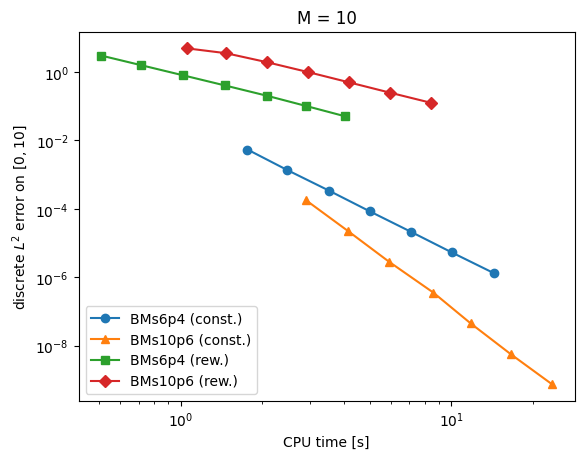

In [15]:
# load the results
data = np.load('FPU_composition_results.npz')

for name, marker in (('BMs6p4', 'o'), ('BMs10p6', '^')):
    plt.loglog(data[f'{name}_const_CPU'], data[f'{name}_const_error'], marker=marker, label=f'{name} (const.)')
for name, marker in (('BMs6p4', 's'), ('BMs10p6', 'D')):
    plt.loglog(data[f'{name}_rew_CPU'], data[f'{name}_rew_error'], marker=marker, label=f'{name} (rew.)')
plt.legend()
plt.title(f"M = {int(data['M'])}")
plt.xlabel(r'CPU time [s]')
plt.ylabel(r'discrete $L^2$ error on $[0,10]$')
matplot2tikz.save('FPU_composition.tex')
plt.show()

## (b) Numerical results for the re-weighting technique

We want to verify that the use of the re-weighting technique lowers the computational cost without significantly sacrificing the overall accuracy.

For this purpose, we investigate the `HOMF4` and the `HFG4` method, both with re-weighting and without re-weighting. To have a fair comparison, the constant multirate factor is chosen as the largest number of micro steps performed by the re-weighted variant,

$$M_{\mathrm{const}} = \max_{j=1,\ldots,s} \lceil \lvert a_j \rvert \cdot M \rceil .$$

Consequently, both variants apply the same number of micro steps for the integrator coefficient of largest modulus, whereas the re-weighting technique reduces the number of applications for integrator coefficients of smaller modulus.

In [ ]:
results = {}
for name in ('HOMF4', 'HFG4'):
    method = methods[name][0]
    M_rew = M_final[name]
    M_const = max_substeps(name, M_rew)
    for M, reweighting, variant in ((M_rew, True, 'rew'), (M_const, False, 'const')):
        CPU_times, global_error = np.zeros(len(nstep_array)), np.zeros(len(nstep_array))
        for i in range(len(nstep_array)):
            CPU_times[i], global_error[i] = run(method, nstep_array[i], M, reweighting)
        results[f'{name}_{variant}_M'] = M
        results[f'{name}_{variant}_CPU'] = CPU_times
        results[f'{name}_{variant}_error'] = global_error
        print(f"{name} ({variant}., M = {M}) done")

# store the results
np.savez('FPU_reweighting_results.npz', nstep_array=nstep_array, **results)
print("results saved in 'FPU_reweighting_results.npz'")

HierarchicalOMF4 (rew., M = 30) done
HierarchicalOMF4 (const., M = 17) done
HierarchicalOmelyan (rew., M = 15) done
HierarchicalOmelyan (const., M = 4) done
results saved in 'FPU_reweighting_results.npz'


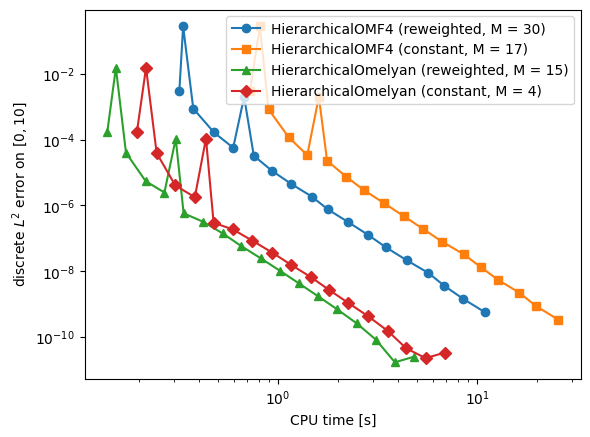

In [ ]:
# load the results
data = np.load('FPU_reweighting_results.npz')

for name, markers in (('HOMF4', ('o', 's')), ('HFG4', ('^', 'D'))):
    for variant, marker, label in (('rew', markers[0], 'reweighted'), ('const', markers[1], 'constant')):
        plt.loglog(data[f'{name}_{variant}_CPU'], data[f'{name}_{variant}_error'], marker=marker,
                   label=f"{name} ({label}, M = {int(data[f'{name}_{variant}_M'])})")
plt.legend()
plt.xlabel(r'CPU time [s]')
plt.ylabel(r'discrete $L^2$ error on $[0,10]$')
matplot2tikz.save('FPU_reweighting.tex')
plt.show()

## (c) Numerical results for COMP4

We perform numerical tests for the `COMP4` method that is only convergent of second order, but for sufficiently large multirate factor $M$ shows a computational order of four. In addition to the fixed multirate factors, we consider the step size-dependent choice $M = 1/h$, for which the method scales with order four over the whole range of step sizes.

In [18]:
mr_array = np.array([100, 200, 300, 400])
nstep_comp4 = tspan[1] * np.array([70, 100, 150, 200, 300, 400, 500]) # h = 1/70, ..., 1/500
global_error = np.zeros((len(mr_array)+1, len(nstep_comp4)))
CPU_times = np.zeros((len(mr_array)+1, len(nstep_comp4)))

for it, M in enumerate(mr_array):
    for i in range(len(nstep_comp4)):
        CPU_times[it,i], global_error[it,i] = run(COMP4, nstep_comp4[i], M, True)
    print(f"M = {M} done")

# step size-dependent multirate factor M(h) = 1/h
for i in range(len(nstep_comp4)):
    CPU_times[-1,i], global_error[-1,i] = run(COMP4, nstep_comp4[i], nstep_comp4[i]//tspan[1], True)
print("M = 1/h done")

# store the results
np.savez('FPU_comp4_results.npz', mr_array=mr_array, nstep_array=nstep_comp4, global_error=global_error, CPU_times=CPU_times)
print("results saved in 'FPU_comp4_results.npz'")

M = 100 done
M = 200 done
M = 300 done
M = 400 done
M = 1/h done
results saved in 'FPU_comp4_results.npz'


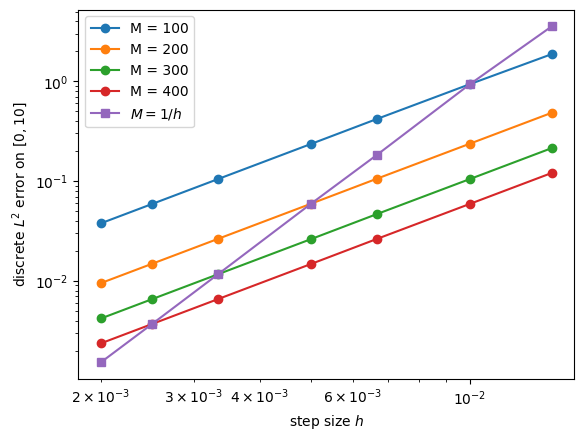

In [19]:
# load the results
data = np.load('FPU_comp4_results.npz')
mr_array = data['mr_array']
nstep_comp4 = data['nstep_array']
global_error = data['global_error']

for it, M in enumerate(mr_array):
    plt.loglog(tspan[1]/nstep_comp4, global_error[it,:], marker='o', label=f'M = {M}')
plt.loglog(tspan[1]/nstep_comp4, global_error[-1,:], marker='s', label=r'$M = 1/h$')
plt.legend()
plt.xlabel(r'step size $h$')
plt.ylabel(r'discrete $L^2$ error on $[0,10]$')
matplot2tikz.save('FPU_comp4.tex')
plt.show()

## (d) Work-precision diagram

For each method, we use the multirate factor that has been tuned manually for the best performance. Starting from the step size grid specified above, the step size is further decreased until the smallest accuracy of interest is reached or a single run exceeds the CPU time budget.

In [20]:
tols = [1e-4, 1e-6, 1e-8] # accuracies compared in the cost table
max_CPU = 120             # the step size is not decreased further once a single run takes longer than max_CPU [s]
ratio = nstep_ratio # geometric ratio of the step sizes


def work_precision(method, M, reweighting):
    """
    runs on the grid nstep_array; the step size is further decreased (with the same ratio)
    until the accuracy min(tols) is reached or a single run takes longer than max_CPU
    """
    nsteps = list(np.sort(nstep_array))
    CPU_times, global_error = map(list, zip(*[run(method, N, M, reweighting) for N in nsteps]))
    while min(global_error) > min(tols) and CPU_times[-1] < max_CPU:
        nsteps.append(int(round(nsteps[-1] * ratio)))
        CPU, error = run(method, nsteps[-1], M, reweighting)
        CPU_times.append(CPU)
        global_error.append(error)
    if min(global_error) > min(tols):
        print(f"   accuracy {min(tols):.0e} not reached (stopped at h*omega = {omega*tspan[1]/nsteps[-1]:.3f})")
    return np.array(nsteps), np.array(CPU_times), np.array(global_error)


results = {}
for name, (method, reweighting) in methods.items():
    M = M_final[name]
    nsteps, CPU_times, global_error = work_precision(method, M, reweighting)
    results[f'{name}_M{M}_nsteps'] = nsteps
    results[f'{name}_M{M}_CPU'] = CPU_times
    results[f'{name}_M{M}_error'] = global_error
    results[f'{name}_M{M}_slow'] = slow_equivalents(name, M, reweighting, nsteps)
    print(f"{name} (M = {M}) done, smallest h*omega = {omega*tspan[1]/nsteps[-1]:.3f}")

# store the results
np.savez('FPU_work-precision_results.npz', tols=tols, kappa_fg=kappa_fg,
         M_final=np.array([M_final[name] for name in methods]), names=np.array(list(methods)), **results)
print("results saved in 'FPU_work-precision_results.npz'")

BMs6p4 (M = 1) done, smallest h*omega = 0.014
BMs10p6 (M = 1) done, smallest h*omega = 0.128
   accuracy 1e-08 not reached (stopped at h*omega = 0.017)
COMP4 (M = 200) done, smallest h*omega = 0.017
HierarchicalOMF4 (M = 30) done, smallest h*omega = 0.200
HierarchicalOmelyan (M = 15) done, smallest h*omega = 0.200
Hierarchicals8p6 (M = 12) done, smallest h*omega = 0.200
results saved in 'FPU_work-precision_results.npz'


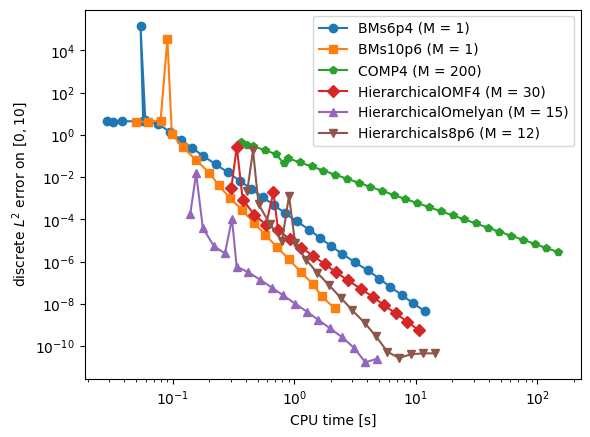

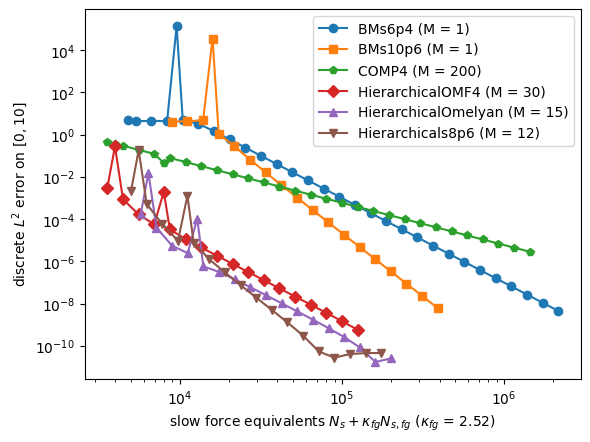

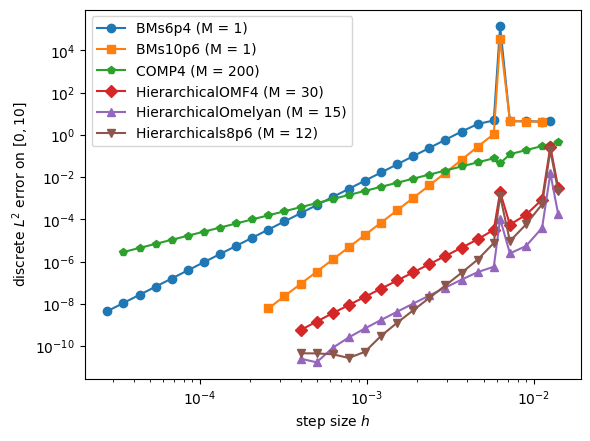

In [21]:
# load the results
data = np.load('FPU_work-precision_results.npz')
names = data['names']
M_final = {name: int(M) for name, M in zip(names, data['M_final'])}
markers = ['o', 's', 'p', 'D', '^', 'v']

# error vs. CPU time
for name, marker in zip(names, markers):
    M = M_final[name]
    plt.loglog(data[f'{name}_M{M}_CPU'], data[f'{name}_M{M}_error'], marker=marker, label=f'{name} (M = {M})')
plt.legend()
plt.xlabel(r'CPU time [s]')
plt.ylabel(r'discrete $L^2$ error on $[0,10]$')
matplot2tikz.save('FPU_work-precision_CPU.tex')
plt.show()

# error vs. slow force equivalents
for name, marker in zip(names, markers):
    M = M_final[name]
    plt.loglog(data[f'{name}_M{M}_slow'], data[f'{name}_M{M}_error'], marker=marker, label=f'{name} (M = {M})')
plt.legend()
plt.xlabel(r'slow force equivalents $N_s + \kappa_{fg} N_{s,fg}$' + f' ($\\kappa_{{fg}}$ = {float(data["kappa_fg"]):.2f})')
plt.ylabel(r'discrete $L^2$ error on $[0,10]$')
matplot2tikz.save('FPU_work-precision_slow.tex')
plt.show()

# convergence
for name, marker in zip(names, markers):
    M = M_final[name]
    plt.loglog(tspan[1]/data[f'{name}_M{M}_nsteps'], data[f'{name}_M{M}_error'], marker=marker, label=f'{name} (M = {M})')
plt.legend()
plt.xlabel(r'step size $h$')
plt.ylabel(r'discrete $L^2$ error on $[0,10]$')
matplot2tikz.save('FPU_convergence.tex')
plt.show()

## Cost to reach a given accuracy

For each accuracy, we pick the cheapest run of the work-precision diagram, i.e. the run with the largest step size whose error is below the tolerance, and report its cost in terms of the force evaluations. The table is exported as a LaTeX file.

In [22]:
data = np.load('FPU_work-precision_results.npz')
names = data['names']
M_final = {name: int(M) for name, M in zip(names, data['M_final'])}
tols = data['tols']


def cost_table(filename):
    """table of the costs of the cheapest runs for the chosen multirate factors"""
    lines = [r'\begin{tabular}{llrrrrrrrr}', r'\toprule',
             r'tol & method & $M$ & $h\omega$ & error & CPU [s] & $N_s$ & $N_{s,fg}$ & $N_f$ & $N_{f,fg}$ \\', r'\midrule']
    print(f"{'tol':>7s} {'method':20s} {'M':>4s} {'h*omega':>8s} {'error':>9s} {'CPU [s]':>8s} "
          f"{'N_s':>9s} {'N_s,fg':>9s} {'N_f':>11s} {'N_f,fg':>11s}")
    for tol in tols:
        for name in names:
            M = M_final[name]
            nsteps, error, CPU = data[f'{name}_M{M}_nsteps'], data[f'{name}_M{M}_error'], data[f'{name}_M{M}_CPU']
            reached = np.where(error <= tol)[0]
            if len(reached) == 0:
                print(f"{tol:7.0e} {name:20s} {M:4d}   accuracy not reached")
                lines.append(rf'{tol:.0e} & \texttt{{{name}}} & {M} & \multicolumn{{7}}{{c}}{{not reached}} \\')
                continue
            i = reached[np.argmin(nsteps[reached])]
            ev = {key: nsteps[i]*val for key, val in evaluations_per_step(name, M, methods[name][1]).items()}
            hw_i = omega*tspan[1]/nsteps[i]
            print(f"{tol:7.0e} {name:20s} {M:4d} {hw_i:8.2f} {error[i]:9.2e} {CPU[i]:8.3f} "
                  f"{ev['slow']:9d} {ev['slow_fg']:9d} {ev['fast']:11d} {ev['fast_fg']:11d}")
            lines.append(rf"{tol:.0e} & \texttt{{{name}}} & {M} & {hw_i:.2f} & {error[i]:.2e} & {CPU[i]:.3f} & "
                         rf"{ev['slow']} & {ev['slow_fg']} & {ev['fast']} & {ev['fast_fg']} \\")
        lines.append(r'\midrule' if tol != tols[-1] else r'\bottomrule')
    lines.append(r'\end{tabular}')
    with open(filename, 'w') as file:
        file.write('\n'.join(lines) + '\n')
    print(f"table saved in '{filename}'")


cost_table('FPU_cost_table.tex')

    tol method                  M  h*omega     error  CPU [s]       N_s    N_s,fg         N_f      N_f,fg
  1e-04 BMs6p4                  1     0.16  8.03e-05    1.050    187320         0      187320           0
  1e-04 BMs10p6                 1     0.61  7.05e-05    0.464     82300         0       82300           0
  1e-04 COMP4                 200     0.08  6.42e-05   31.213    304015         0    13863084           0
  1e-04 HierarchicalOMF4       30     3.59  5.65e-05    0.586      6955         0      243425           0
  1e-04 HierarchicalOmelyan    15     5.61  3.99e-05    0.177      2676      1784       42816       28544
  1e-04 Hierarchicals8p6       12     4.49  5.79e-05    0.634      7798         0      265132           0
  1e-06 BMs6p4                  1     0.05  9.43e-07    3.144    568950         0      568950           0
  1e-06 BMs10p6                 1     0.25  3.34e-07    1.128    200190         0      200190           0
  1e-06 COMP4                 200   accuracy n

## (e) Investigations of the maximum relative energy error

Finally, we investigate the robustness of the methods with respect to the step size. In contrast to the preceding tests, the maximum relative energy error does not require a reference solution.

The `HOMF4` and the `HOMF6` method are each compared with the composition scheme of the same order, both with its tuned multirate factor and with a constant multirate factor for which the number of force evaluations and the CPU time per step match those of the respective hierarchical splitting method. A run counts as a breakdown if it overflows or if the maximum relative energy error exceeds `stab_tol`.

In [ ]:
hw_stab = np.arange(0.25, 5*np.pi + 1e-12, 0.05) # h*omega
nstep_stab = np.round(tspan[1]*omega/hw_stab).astype(int)
nstep_kpi = np.round(tspan[1]*omega/(np.pi*np.arange(1, 6))).astype(int) # resonances h*omega = k*pi, k = 1, ..., 5
nstep_stab = np.unique(np.concatenate((nstep_stab, nstep_kpi)))[::-1]
hw_stab = omega*tspan[1]/nstep_stab # actual values of h*omega
stab_tol = 1.0 # a run counts as breakdown if it overflows or if the max. relative energy error exceeds stab_tol


def max_energy_error(x):
    """maximum relative energy error along the numerical solution x (shape (2d,nsteps+1))"""
    p, q = x[:2*m], x[2*m:]
    energy = 0.5*np.sum(p*p, axis=0) + 0.25*np.sum((D @ q)**4, axis=0) + 0.5*omega**2*np.sum(q[m:]*q[m:], axis=0)
    return np.max(np.abs(energy - energy[0])) / np.abs(energy[0])


# for fixed M, the largest micro step of the fast node is omega*tau_max = c_max*h*omega
stab_runs = [('HOMF4', M_final['HOMF4']), ('BMs6p4', M_final['BMs6p4']), ('BMs6p4', 15),
             ('HOMF6', M_final['HOMF6']), ('BMs10p6', M_final['BMs10p6']), ('BMs10p6', 12)]
stab_runs = list(dict.fromkeys(stab_runs))

results = {}
for name, M in stab_runs:
    method, reweighting = methods[name]
    c_max = max(abs(a) / n_substeps(a, M, reweighting) for a in stage_weights[name])
    energy_error = np.zeros(len(nstep_stab))
    for i in range(len(nstep_stab)):
        try:
            t,x = method(x0, tspan, nstep_stab[i], M, reweighting)
            energy_error[i] = max_energy_error(x)
        except FloatingPointError:
            energy_error[i] = np.inf
    results[f'{name}_M{M}_energy_error'] = energy_error
    unstable = hw_stab[~(energy_error <= stab_tol)]
    print(f"{name:20s} (M = {M:3d}, omega*tau_max = {c_max:.3f}*h*omega): first breakdown at h*omega = "
          f"{unstable[0] if len(unstable) else np.nan:.2f}, breakdown in {len(unstable)} of {len(hw_stab)} runs, "
          f"breakdown at h*omega: {np.round(unstable, 2)}")

# store the results
np.savez('FPU_stability_results.npz', hw_stab=hw_stab, stab_tol=stab_tol,
         names=np.array([name for name, _ in stab_runs]), Ms=np.array([M for _, M in stab_runs]), **results)
print("results saved in 'FPU_stability_results.npz'")

HierarchicalOMF4     (M =  30, omega*tau_max = 0.033*h*omega): first breakdown at h*omega = 12.44, breakdown in 3 of 313 runs, breakdown at h*omega: [12.44 12.59 12.69]
BMs6p4               (M =   1, omega*tau_max = 0.367*h*omega): first breakdown at h*omega = 3.14, breakdown in 185 of 313 runs, breakdown at h*omega: [ 3.14  3.15  6.2   6.25  6.28  6.3   6.35  6.4   6.45  6.5   6.55  6.6
  6.65  6.7   6.75  6.8   6.85  6.9   6.95  7.    7.05  7.1   7.15  7.2
  7.25  7.3   7.35  7.4   7.45  7.5   8.05  8.1   8.16  8.2   8.25  8.31
  8.35  8.4   8.45  8.5   8.55  8.61  8.65  8.7   8.76  8.8   8.85  8.9
  8.94  8.99  9.06  9.11  9.16  9.21  9.24  9.29  9.35  9.4   9.42  9.45
  9.51  9.54  9.6   9.65  9.71  9.75  9.8   9.84  9.9   9.94 10.   10.04
 10.1  10.14 10.2  10.25 10.31 10.35 10.4  10.46 10.5  10.55 10.59 10.66
 10.71 10.75 10.8  10.85 10.89 10.94 10.99 11.06 11.11 11.16 11.21 11.26
 11.31 11.34 11.39 11.44 11.49 11.55 11.6  11.66 11.71 11.74 11.79 11.85
 11.9  11.96 11.99 12.05 12

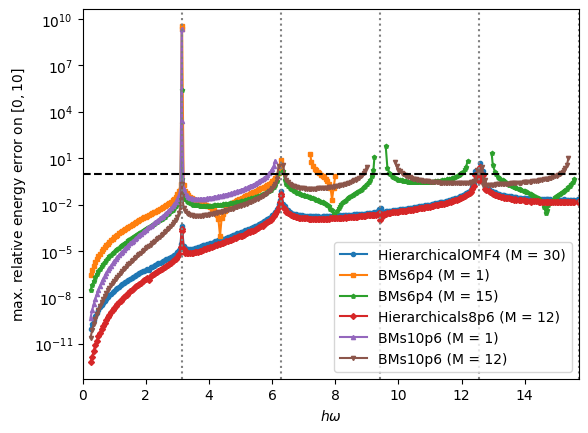

In [26]:
# load the results
data = np.load('FPU_stability_results.npz')
hw_stab = data['hw_stab']
markers = ['o', 's', 'p', 'D', '^', 'v']

for name, M, marker in zip(data['names'], data['Ms'], markers):
    plt.semilogy(hw_stab, data[f'{name}_M{M}_energy_error'], marker=marker, markersize=3, label=f'{name} (M = {M})')
for k in range(1, 6):
    plt.axvline(k*np.pi, color='gray', linestyle=':')
plt.axhline(float(data['stab_tol']), color='black', linestyle='--')
plt.xlim(0, 5*np.pi)
plt.legend()
plt.xlabel(r'$h\omega$')
plt.ylabel(r'max. relative energy error on $[0,10]$')
matplot2tikz.save('FPU_stability.tex')
plt.show()